<a href="https://colab.research.google.com/github/vijaygubaxani/MachineLearning/blob/main/Scaler_Clustering_Busienss_Case_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

📊 Scaler Case Study Architecture🎯 1. Business Objective & EDA (10 Points)Goal: Group Scaler learners by profile to find top-paying companies and high-growth roles.Structure: Check dataset size (shape), data types (dtypes), duplicates, and Email_hash frequency.Summary: Run 5-point summaries (mean, median, min, max, count) and detect missing values.Plots: Use univariate charts for distributions and bivariate charts to link experience/roles to CTC.🛠️ 2. Data Cleaning & Engineering (30 Points)Regex: Clean messy user text in Company_hash and Job_position by removing special characters.Imputation: Handle missing data using Mean or KNN (K-Nearest Neighbors) imputation.Experience: Create a Years of Experience column by subtracting orgyear from the current year.Encoding & Scaling: Apply One-Hot/Label encoding and StandardScaler to prep data for clustering.🧮 3. Manual Clustering & Benchmarking (30 Points)Designation Flag: Benchmark CTC against the average of the same company, job, and experience. Mark 1 (above), 2 (average), or 3 (below).Class Flag: Benchmark CTC at the broader Company & Job Position level (ignore experience). Mark 1, 2, or 3.Tier Flag: Benchmark CTC strictly at the Company level to rank employers. Mark 1, 2, or 3.Talent Insights: Extract specific lists:Top and bottom 10 overall earners (Tier 1 vs Tier 3).Top and bottom 10 Data Science earners per company (Class 1 vs Class 3).Top 10 peers with exactly 5, 6, or 7 years of experience in specific departments.Top 10 highest-paying companies and top 2 roles within each.🤖 4. Unsupervised Machine Learning (20 Points)Tendency: Test if the data has natural, valid clusters before modeling.K-Means: Run K-Means and use the Elbow Method plot to find the optimal cluster count (K).Hierarchical: Run agglomerative clustering (use a sample if slow) and plot a dendrogram.Profiling: Compare machine-generated clusters with your manual salary flags to find patterns.📈 5. Actionable Insights (10 Points)Strategy: Turn data into business choices (e.g., align courses with top-paying roles, target Tier 1 partners, and find underpaid talent for premium placement).

In [5]:
import pandas as pd

df_students = pd.read_csv('/content/sample_data/scaler_hashed_for_students.csv')
df_job_positions = pd.read_csv('/content/sample_data/scaler_job_positions_mapping VX.csv')



In [77]:
# df_students.head()

In [78]:
# df_students.info()

In [79]:
# df_job_positions.head()

In [10]:
df_job_positions['New'].nunique()

580

In [80]:
# df_job_positions.info()

In [23]:
#one data row check for an email
df_students[df_students['email_hash'] == df_students['email_hash'].iloc[2]]

,Unnamed: 0,company_hash,email_hash,orgyear,ctc,job_position,ctc_updated_year
2,2,faulwklwsl ks,4860c670bcd48fb96c02a4b0ae3608ae6fdd98176112e9...,2015.0,2000000,Backend Engineer,2020.0
201840,202903,litijiow,4860c670bcd48fb96c02a4b0ae3608ae6fdd98176112e9...,2015.0,1550000,Backend Engineer,2019.0


### Univariate Analysis

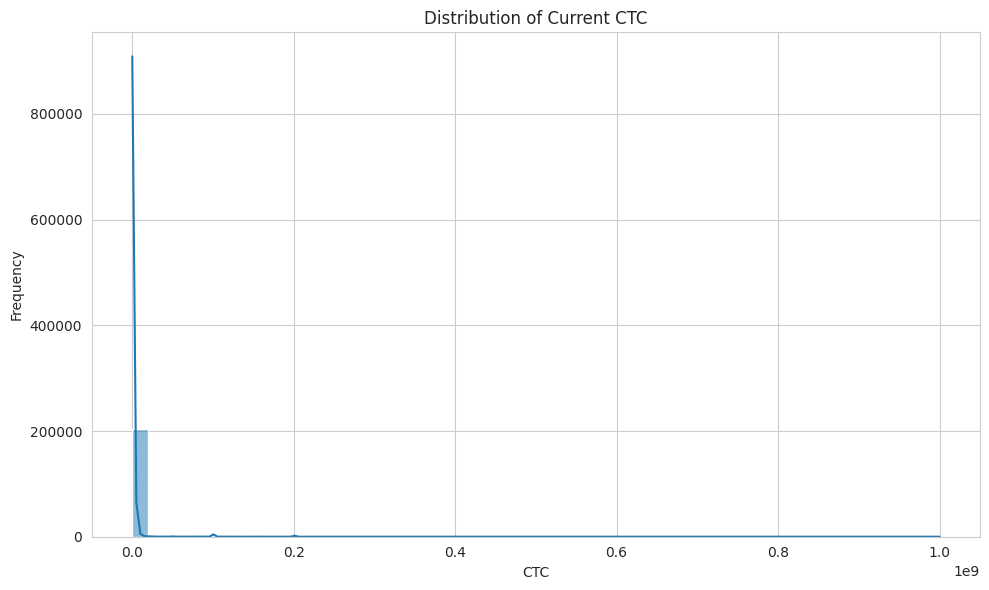

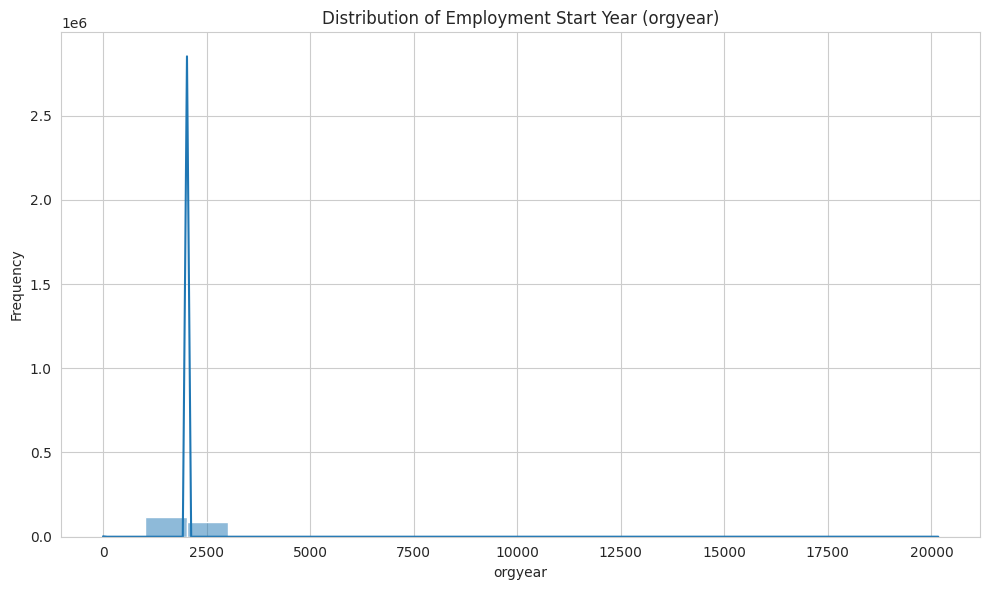

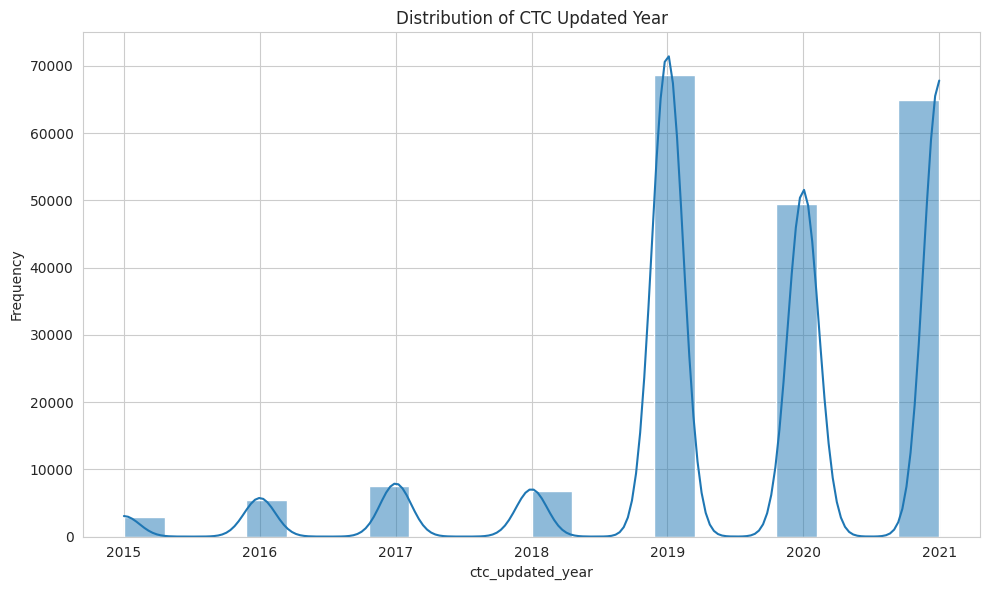

In [105]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

def plot_histogram(data, column, bins=50, kde=True, title='', xlabel='', ylabel=''):
    """Helper function to plot histograms."""
    plt.figure(figsize=(10, 6))
    sns.histplot(data[column], bins=bins, kde=kde)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

# Distribution of 'ctc' (Current CTC)
plot_histogram(df_students, 'ctc', title='Distribution of Current CTC', xlabel='CTC', ylabel='Frequency')

# Distribution of 'orgyear' (Employment start date)
plot_histogram(df_students, 'orgyear', bins=20, title='Distribution of Employment Start Year (orgyear)', xlabel='orgyear', ylabel='Frequency')

# Distribution of 'ctc_updated_year'
plot_histogram(df_students, 'ctc_updated_year', bins=20, title='Distribution of CTC Updated Year', xlabel='ctc_updated_year', ylabel='Frequency')

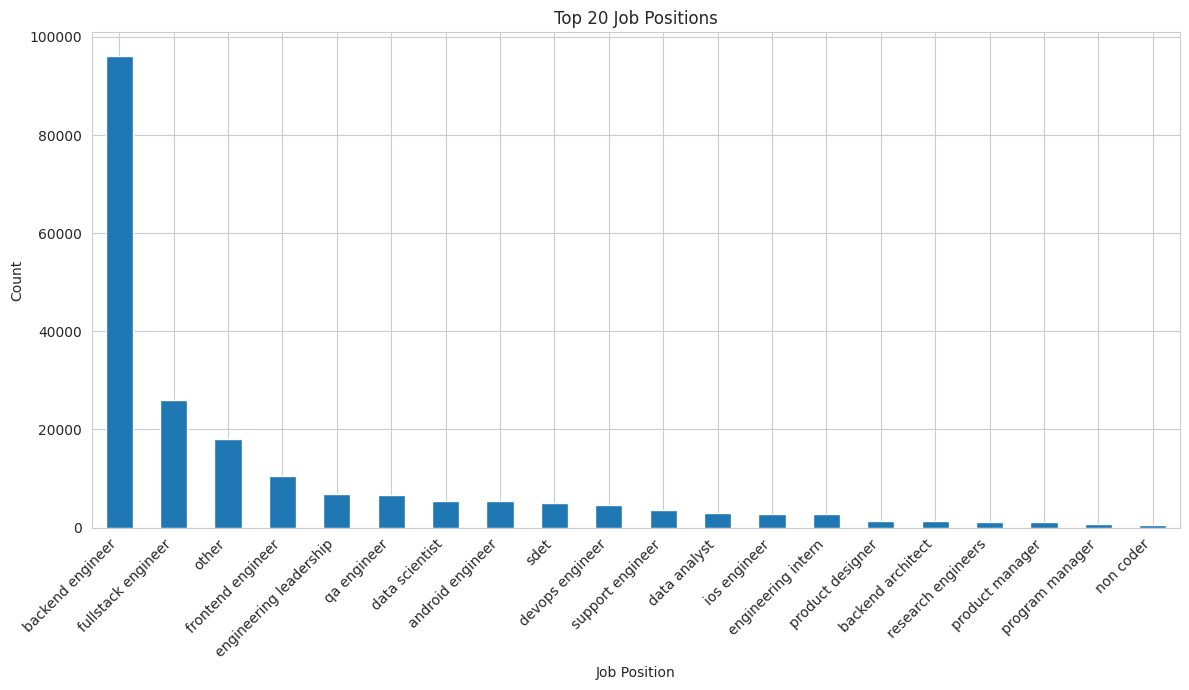

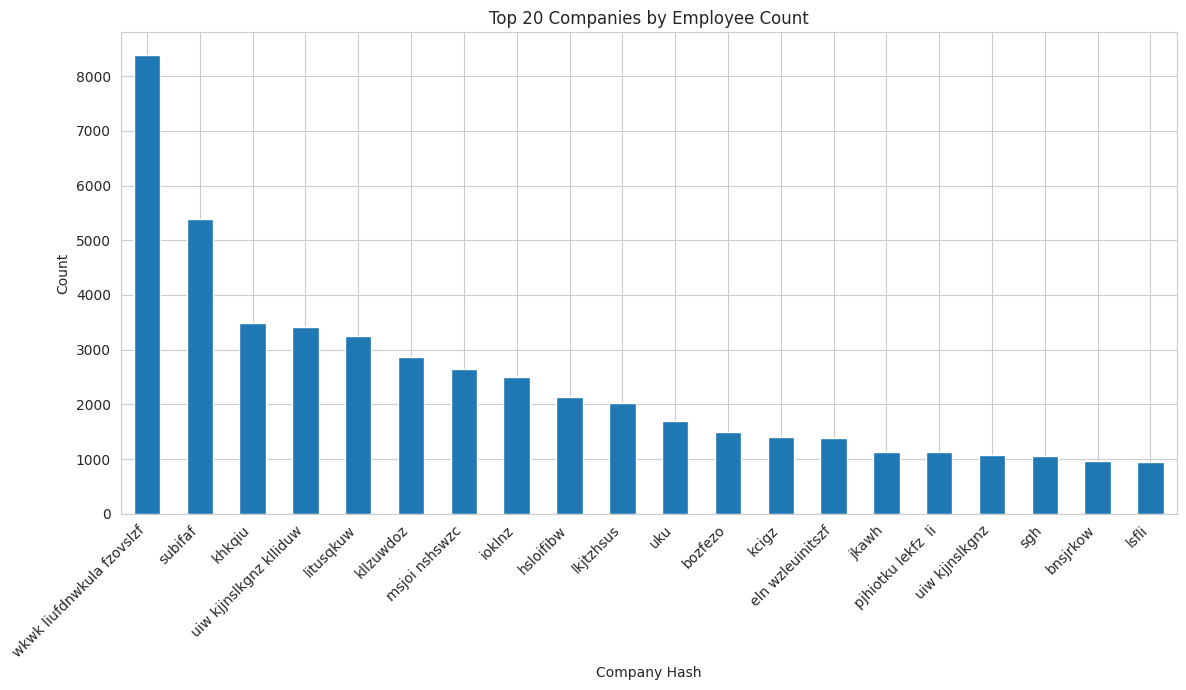

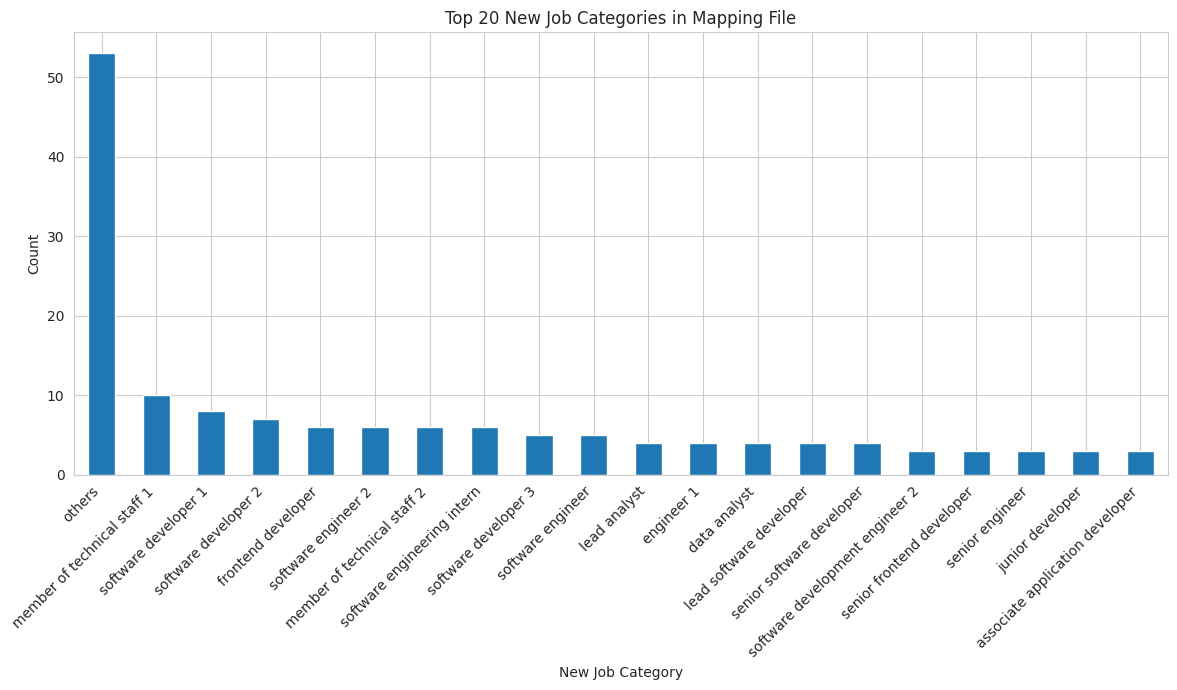

In [106]:
def plot_bar(data, column, title='', xlabel='', ylabel='', n_largest=20):
    """Helper function to plot bar charts for top N categorical values."""
    plt.figure(figsize=(12, 7))
    data[column].value_counts().nlargest(n_largest).plot(kind='bar')
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# df_students: Top Job Positions
plot_bar(df_students, 'job_position', title='Top 20 Job Positions', xlabel='Job Position', ylabel='Count')

# df_students: Top Companies by Employee Count
plot_bar(df_students, 'company_hash', title='Top 20 Companies by Employee Count', xlabel='Company Hash', ylabel='Count')

# df_job_positions: Top New Job Categories in Mapping File
plot_bar(df_job_positions, 'New', title='Top 20 New Job Categories in Mapping File', xlabel='New Job Category', ylabel='Count')

### Data Pre-processing: Missing Values and Regex Cleaning

In [107]:
import re

def clean_text(text):
    if pd.isnull(text):
        return text
    cleaned_text = re.sub('[^A-Za-z0-9 ]+', '', str(text))
    return cleaned_text.strip().lower()

df_students['company_hash'] = df_students['company_hash'].apply(clean_text)
df_students['job_position'] = df_students['job_position'].apply(clean_text)
df_job_positions['Original'] = df_job_positions['Original'].apply(clean_text)
df_job_positions['New'] = df_job_positions['New'].apply(clean_text)

# Imputing missing values - using direct assignment instead of inplace=True
if df_students['company_hash'].isnull().any():
    mode_company_hash = df_students['company_hash'].mode()[0]
    df_students['company_hash'] = df_students['company_hash'].fillna(mode_company_hash)

if df_students['orgyear'].isnull().any():
    median_orgyear = df_students['orgyear'].median()
    df_students['orgyear'] = df_students['orgyear'].fillna(median_orgyear)

if df_students['job_position'].isnull().any():
    mode_job_position = df_students['job_position'].mode()[0]
    df_students['job_position'] = df_students['job_position'].fillna(mode_job_position)

if df_job_positions['Original'].isnull().any():
    mode_original_jp = df_job_positions['Original'].mode()[0]
    df_job_positions['Original'] = df_job_positions['Original'].fillna(mode_original_jp)

### Data Pre-processing: Duplicates and Feature Engineering

In [108]:
# Checking for duplicates and dropping them
initial_rows = df_students.shape[0]
df_students.drop_duplicates(inplace=True)
duplicates_removed = initial_rows - df_students.shape[0]
print(f"Number of duplicate rows removed from df_students: {duplicates_removed}")

# Making new features like 'Years of Experience'
current_year = pd.to_datetime('today').year
df_students['years_of_experience'] = current_year - df_students['orgyear']
df_students['years_of_experience'] = df_students['years_of_experience'].astype(int)

Number of duplicate rows removed from df_students: 0


### Manual Clustering: CTC Summary

In [109]:
ctc_summary = df_students.groupby(['company_hash', 'job_position', 'years_of_experience'])['ctc'].agg(
    ['mean', 'median', 'min', 'max', 'count']
).reset_index()

ctc_summary.rename(columns={
    'mean': 'avg_ctc_company_job_exp',
    'median': 'median_ctc_company_job_exp',
    'min': 'min_ctc_company_job_exp',
    'max': 'max_ctc_company_job_exp',
    'count': 'count_employees_company_job_exp'
}, inplace=True)

In [110]:
import re

# Define base columns from ctc_summary and the flag that will be created
ctc_summary_base_cols = ['avg_ctc_company_job_exp', 'median_ctc_company_job_exp',
                         'min_ctc_company_job_exp', 'max_ctc_company_job_exp',
                         'count_employees_company_job_exp']
all_cols_to_check = ctc_summary_base_cols + ['designation']

# Construct a regex pattern to match base columns and their _x, _y variants
cols_pattern = '|'.join([re.escape(col) + r'(_x|_y)?$' for col in all_cols_to_check])
existing_cols_to_drop = [col for col in df_students.columns if re.match(cols_pattern, col)]

if existing_cols_to_drop:
    df_students = df_students.drop(columns=existing_cols_to_drop)
    # print(f"Dropped existing conflicting columns from df_students: {existing_cols_to_drop}")

df_students = pd.merge(df_students,
                       ctc_summary,
                       on=['company_hash', 'job_position', 'years_of_experience'],
                       how='left')

# Handle potential NaN values from merge (impute with overall median CTC if specific group average is missing)
if df_students['avg_ctc_company_job_exp'].isnull().any():
    overall_median_ctc = df_students['ctc'].median()
    df_students['avg_ctc_company_job_exp'] = df_students['avg_ctc_company_job_exp'].fillna(overall_median_ctc)
    # print(f"Filled NaN avg_ctc_company_job_exp with overall median CTC: {overall_median_ctc}")

# Define a small tolerance for floating point comparisons
tolerance = 0.01 * df_students['ctc'].mean()

def get_designation(row):
    if row['ctc'] > row['avg_ctc_company_job_exp'] + tolerance:
        return 1
    elif abs(row['ctc'] - row['avg_ctc_company_job_exp']) <= tolerance:
        return 2
    else:
        return 3

df_students['designation'] = df_students.apply(get_designation, axis=1)

### Manual Clustering: Creating 'Class' Flag

In [111]:
import re

ctc_summary_company_job = df_students.groupby(['company_hash', 'job_position'])['ctc'].agg(
    ['mean', 'median', 'min', 'max', 'count']
).reset_index()

ctc_summary_company_job.rename(columns={
    'mean': 'avg_ctc_company_job',
    'median': 'median_ctc_company_job',
    'min': 'min_ctc_company_job',
    'max': 'max_ctc_company_job',
    'count': 'count_employees_company_job'
}, inplace=True)

# Define base columns from ctc_summary_company_job and the flag that will be created
ctc_summary_company_job_base_cols = ['avg_ctc_company_job', 'median_ctc_company_job',
                                        'min_ctc_company_job', 'max_ctc_company_job',
                                        'count_employees_company_job']
all_cols_to_check = ctc_summary_company_job_base_cols + ['class_flag']

# Construct a regex pattern to match base columns and their _x, _y variants
cols_pattern = '|'.join([re.escape(col) + r'(_x|_y)?$' for col in all_cols_to_check])
existing_cols_to_drop = [col for col in df_students.columns if re.match(cols_pattern, col)]

if existing_cols_to_drop:
    df_students = df_students.drop(columns=existing_cols_to_drop)
    # print(f"Dropped existing conflicting columns from df_students: {existing_cols_to_drop}")

df_students = pd.merge(df_students,
                       ctc_summary_company_job,
                       on=['company_hash', 'job_position'],
                       how='left')

# Handle potential NaN values from merge
if df_students['avg_ctc_company_job'].isnull().any():
    overall_median_ctc = df_students['ctc'].median()
    df_students['avg_ctc_company_job'] = df_students['avg_ctc_company_job'].fillna(overall_median_ctc)
    # print(f"Filled NaN avg_ctc_company_job with overall median CTC: {overall_median_ctc}")

tolerance = 0.01 * df_students['ctc'].mean()

def get_class(row):
    if row['ctc'] > row['avg_ctc_company_job'] + tolerance:
        return 1
    elif abs(row['ctc'] - row['avg_ctc_company_job']) <= tolerance:
        return 2
    else:
        return 3

df_students['class_flag'] = df_students.apply(get_class, axis=1)

### Manual Clustering: Creating 'Tier' Flag

In [112]:
import re

ctc_summary_company = df_students.groupby(['company_hash'])['ctc'].agg(
    ['mean', 'median', 'min', 'max', 'count']
).reset_index()

ctc_summary_company.rename(columns={
    'mean': 'avg_ctc_company',
    'median': 'median_ctc_company',
    'min': 'min_ctc_company',
    'max': 'max_ctc_company',
    'count': 'count_employees_company'
}, inplace=True)

# Define base columns from ctc_summary_company and the flag that will be created
ctc_summary_company_base_cols = ['avg_ctc_company', 'median_ctc_company',
                                     'min_ctc_company', 'max_ctc_company',
                                     'count_employees_company']
all_cols_to_check = ctc_summary_company_base_cols + ['tier_flag']

# Construct a regex pattern to match base columns and their _x, _y variants
cols_pattern = '|'.join([re.escape(col) + r'(_x|_y)?$' for col in all_cols_to_check])
existing_cols_to_drop = [col for col in df_students.columns if re.match(cols_pattern, col)]

if existing_cols_to_drop:
    df_students = df_students.drop(columns=existing_cols_to_drop)
    # print(f"Dropped existing conflicting columns from df_students: {existing_cols_to_drop}")

df_students = pd.merge(df_students,
                       ctc_summary_company,
                       on=['company_hash'],
                       how='left')

# Handle potential NaN values from merge
if df_students['avg_ctc_company'].isnull().any():
    overall_median_ctc = df_students['ctc'].median()
    df_students['avg_ctc_company'] = df_students['avg_ctc_company'].fillna(overall_median_ctc)
    # print(f"Filled NaN avg_ctc_company with overall median CTC: {overall_median_ctc}")

tolerance = 0.01 * df_students['ctc'].mean()

def get_tier(row):
    if row['ctc'] > row['avg_ctc_company'] + tolerance:
        return 1
    elif abs(row['ctc'] - row['avg_ctc_company']) <= tolerance:
        return 2
    else:
        return 3

df_students['tier_flag'] = df_students.apply(get_tier, axis=1)

## Answering Business Questions with Manual Clusters

### Q1: Top 10 employees (earning more than most of the employees in the company) - Tier 1

In [113]:
# Q1: Top 10 employees (earning more than most of the employees in the company) - Tier 1
top_tier1_employees = df_students[df_students['tier_flag'] == 1].sort_values(by='ctc', ascending=False).head(10)

# display(top_tier1_employees[['email_hash', 'company_hash', 'job_position', 'ctc', 'years_of_experience', 'tier_flag']])

### Q2: Top 10 employees of data science in each company earning more than their peers - Class 1

In [114]:
# Q2: Top 10 employees of data science in each company earning more than their peers - Class 1

# Define keywords for data science related job positions
data_science_keywords = ['data scientist', 'data analyst', 'machine learning engineer', 'ai engineer', 'ml engineer', 'data science', 'analyst']

# Filter for data science related job positions and class_flag == 1
data_science_class1_employees = df_students[
    (df_students['job_position'].str.contains('|'.join(data_science_keywords), na=False, case=False)) &
    (df_students['class_flag'] == 1)
]

# Group by company and get the top 10 based on CTC for each company
top_data_science_class1_by_company = data_science_class1_employees.groupby('company_hash', group_keys=False).apply(
    lambda x: x.sort_values(by='ctc', ascending=False).head(10)
).reset_index(drop=True)

# display(top_data_science_class1_by_company[
#     ['email_hash', 'company_hash', 'job_position', 'ctc', 'years_of_experience', 'class_flag']
# ])

/tmp/ipykernel_682/887302048.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top_data_science_class1_by_company = data_science_class1_employees.groupby('company_hash', group_keys=False).apply(


### Q3: Bottom 10 employees of data science in each company earning less than their peers - Class 3

In [115]:
# Q3: Bottom 10 employees of data science in each company earning less than their peers - Class 3

# Filter for data science related job positions and class_flag == 3
data_science_class3_employees = df_students[
    (df_students['job_position'].str.contains('|'.join(data_science_keywords), na=False, case=False)) &
    (df_students['class_flag'] == 3)
]

# Group by company and get the bottom 10 based on CTC for each company
top_data_science_class3_by_company = data_science_class3_employees.groupby('company_hash', group_keys=False).apply(
    lambda x: x.sort_values(by='ctc', ascending=True).head(10)
).reset_index(drop=True)

# display(top_data_science_class3_by_company[
#     ['email_hash', 'company_hash', 'job_position', 'ctc', 'years_of_experience', 'class_flag']
# ])

/tmp/ipykernel_682/1256045123.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top_data_science_class3_by_company = data_science_class3_employees.groupby('company_hash', group_keys=False).apply(


### Q4: Bottom 10 employees (earning less than most of the employees in the company) - Tier 3

In [116]:
# Q4: Bottom 10 employees (earning less than most of the employees in the company) - Tier 3

bottom_tier3_employees = df_students[df_students['tier_flag'] == 3].sort_values(by='ctc', ascending=True).head(10)

# display(bottom_tier3_employees[['email_hash', 'company_hash', 'job_position', 'ctc', 'years_of_experience', 'tier_flag']])

### Q5: Top 10 employees in each company (Software Engineering roles, 5-7 YOE, Designation 1)

In [117]:
# Q5: Top 10 employees in each company - X department - having 5/6/7 years of experience earning more than their peers - Designation 1

# Define keywords for software engineering related job positions
software_engineering_keywords = [
    'software engineer', 'backend engineer', 'frontend engineer',
    'fullstack engineer', 'devops engineer', 'android engineer', 'ios engineer'
]

# Filter for software engineering related job positions, years of experience, and designation == 1
software_eng_designation1_employees = df_students[
    (df_students['job_position'].str.contains('|'.join(software_engineering_keywords), na=False, case=False)) &
    (df_students['years_of_experience'].isin([5, 6, 7])) &
    (df_students['designation'] == 1)
]

# Group by company and get the top 10 based on CTC for each company
top_software_eng_by_company = software_eng_designation1_employees.groupby('company_hash', group_keys=False).apply(
    lambda x: x.sort_values(by='ctc', ascending=False).head(10)
).reset_index(drop=True)

# display(top_software_eng_by_company[
#     ['email_hash', 'company_hash', 'job_position', 'ctc', 'years_of_experience', 'designation']
# ])

/tmp/ipykernel_682/3371712105.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top_software_eng_by_company = software_eng_designation1_employees.groupby('company_hash', group_keys=False).apply(


### Q6: Top 10 companies (based on their CTC)

In [118]:
# Q6: Top 10 companies (based on their CTC)

top_10_companies_by_ctc = df_students.groupby('company_hash')['ctc'].mean().sort_values(ascending=False).head(10)

# display(top_10_companies_by_ctc)

### Q7: Top 2 positions in every company (based on their CTC)

In [119]:
# Q7: Top 2 positions in every company (based on their CTC)

# Calculate average CTC for each job position within each company
avg_ctc_by_company_job = df_students.groupby(['company_hash', 'job_position'])['ctc'].mean().reset_index()

# Sort by CTC in descending order within each company and get the top 2 positions
top_2_positions_per_company = avg_ctc_by_company_job.groupby('company_hash', group_keys=False).apply(
    lambda x: x.sort_values(by='ctc', ascending=False).head(2)
).reset_index(drop=True)

# display(top_2_positions_per_company)

/tmp/ipykernel_682/4181544643.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top_2_positions_per_company = avg_ctc_by_company_job.groupby('company_hash', group_keys=False).apply(


## Data Processing for Unsupervised Clustering

To prepare the data for clustering algorithms like K-Means or Hierarchical Clustering, we need to perform two main steps:

1.  **Encoding Categorical Features**: Convert text-based categorical columns into numerical representations.
2.  **Standardization**: Scale numerical features to have a mean of 0 and a standard deviation of 1. This ensures that features with larger values do not disproportionately influence the distance calculations in clustering.

### Encoding Categorical Features

For `company_hash` and `job_position`, which have many unique values (high cardinality), we will use `LabelEncoder`. While One-Hot Encoding would be suitable for low-cardinality features, it would create too many columns for these features, making the dataset very sparse and potentially difficult for clustering in a beginner-friendly approach. Label Encoding assigns a unique integer to each category, which is simpler, though it implies an ordinal relationship that doesn't exist.

In [120]:
from sklearn.preprocessing import LabelEncoder

df_clustering = df_students.copy()
df_clustering = df_clustering.drop(columns=['Unnamed: 0', 'email_hash'])

le = LabelEncoder()
df_clustering['company_hash_encoded'] = le.fit_transform(df_clustering['company_hash'])
df_clustering['job_position_encoded'] = le.fit_transform(df_clustering['job_position'])

df_clustering = df_clustering.drop(columns=['company_hash', 'job_position'])

### Standardization of Numerical Data

Next, we'll standardize the numerical features, including the newly created `years_of_experience` and the `designation`, `class_flag`, and `tier_flag`. This step is crucial for distance-based clustering algorithms, as it prevents features with larger scales from dominating the clustering results.

In [121]:
from sklearn.preprocessing import StandardScaler

numerical_features = [
    'orgyear',
    'ctc',
    'ctc_updated_year',
    'years_of_experience',
    'avg_ctc_company_job_exp',
    'median_ctc_company_job_exp',
    'min_ctc_company_job_exp',
    'max_ctc_company_job_exp',
    'count_employees_company_job_exp',
    'avg_ctc_company_job',
    'median_ctc_company_job',
    'min_ctc_company_job',
    'max_ctc_company_job',
    'count_employees_company_job',
    'avg_ctc_company',
    'median_ctc_company',
    'min_ctc_company',
    'max_ctc_company',
    'count_employees_company',
    'designation',
    'class_flag',
    'tier_flag'
]

numerical_features = [col for col in numerical_features if col in df_clustering.columns]

# print(f"Numerical features to be standardized: {numerical_features}")

scaler = StandardScaler()
df_clustering[numerical_features] = scaler.fit_transform(df_clustering[numerical_features])

## Insights from Unsupervised Clustering

After performing K-Means and Hierarchical clustering, the next crucial step is to understand the characteristics of the clusters we've identified. This involves analyzing the features that define each cluster to gain meaningful business insights.

### K-Means Cluster Analysis

Let's examine the average values of the original (unscaled) features for each K-Means cluster to understand their profiles. We will re-merge the cluster labels with the original `df_students` for easier interpretation using unscaled data.

In [122]:
from sklearn.cluster import KMeans

# Ensure X (scaled data) is explicitly defined from df_clustering before K-Means
# This assumes df_clustering has been standardized and encoded as intended by previous cells.
X = df_clustering.values

# Ensure optimal_k is defined, if not, set a default (e.g., 4, as chosen previously)
if 'optimal_k' not in locals() or 'optimal_k' not in globals():
    optimal_k = 4

# Re-apply K-Means clustering to ensure 'kmeans_cluster' column exists in df_clustering
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
df_clustering['kmeans_cluster'] = kmeans.fit_predict(X)

df_original_with_clusters = df_students.copy()
df_original_with_clusters['kmeans_cluster'] = df_clustering['kmeans_cluster']

cluster_means = df_original_with_clusters.groupby('kmeans_cluster')[[    'ctc', 'years_of_experience', 'orgyear', 'ctc_updated_year',
    'designation', 'class_flag', 'tier_flag'
]].mean().sort_values(by='ctc', ascending=False)

print("Average feature values per K-Means cluster (sorted by average CTC):")
display(cluster_means)

print("\nMost frequent job positions and companies per K-Means cluster:")
for i in range(optimal_k):
    job_mode = df_original_with_clusters[df_original_with_clusters['kmeans_cluster'] == i]['job_position'].mode()[0]
    company_mode = df_original_with_clusters[df_original_with_clusters['kmeans_cluster'] == i]['company_hash'].mode()[0]
    print(f"Cluster {i}: Most common Job Position = '{job_mode}', Most common Company = '{company_mode}'")

Average feature values per K-Means cluster (sorted by average CTC):


,ctc,years_of_experience,orgyear,ctc_updated_year,designation,class_flag,tier_flag
kmeans_cluster,,,,,,,
1,2.388554e+06,11.506509,2014.493491,2019.531673,2.092464,2.219594,2.344211
0,2.305081e+06,10.908664,2015.091336,2019.738413,2.196662,2.330763,2.463771
2,2.288298e+06,11.651382,2014.348618,2019.539424,2.112656,2.234158,2.331510
3,2.115402e+06,10.468347,2015.531653,2019.681363,2.175681,2.328709,2.425435



Most frequent job positions and companies per K-Means cluster:
Cluster 0: Most common Job Position = 'backend engineer', Most common Company = 'wkwk liufdnwkula fzovslzf'
Cluster 1: Most common Job Position = 'backend engineer', Most common Company = 'bozfezo'
Cluster 2: Most common Job Position = 'backend engineer', Most common Company = 'khkqiu'
Cluster 3: Most common Job Position = 'backend engineer', Most common Company = 'subifaf'


## Actionable Insights & Recommendations for the Business

Based on the manual clustering (designation, class, tier flags) and the unsupervised clustering (K-Means), we can now formulate actionable insights and recommendations for Scaler.

In [123]:
## Actionable Insights & Recommendations for the Business

### Summary of Key Findings:

**From Manual Clustering (Flags):**
- **Top Performers (Tier 1, Class 1, Designation 1):** We identified specific employees and companies that stand out based on their CTC relative to their peers. These individuals often have higher CTCs within their company, job role, and experience level.
- **Areas for Improvement (Tier 3, Class 3, Designation 3):** Similarly, we pinpointed employees earning significantly less than their peers. This could indicate potential dissatisfaction or underutilization of skills.
- **Top Companies/Positions (Q6, Q7):** We've highlighted companies with the highest average CTCs and the most lucrative job positions within each company.

**From Unsupervised Clustering (K-Means):**
- We identified distinct groups (clusters) of employees based on their combined features (CTC, experience, company, job role, and flags).
- Each cluster represents a different employee profile, characterized by average CTC, years of experience, and predominant job roles/companies. For example, one cluster might consist of high-earning, experienced professionals, while another might be newer entrants with lower CTCs.
- Understanding these clusters helps segment the employee base naturally, without pre-defined rules.

### Actionable Recommendations for Scaler:

1.  **Targeted Career Development for Lower-Tier Employees:** For employees identified in Tier 3/Class 3/Designation 3, Scaler can offer specialized upskilling programs or mentorship to help them improve their CTC and career progression. This could involve focusing on in-demand skills relevant to higher-paying roles within their companies or in target companies.
2.  **High-Performer Retention Strategies:** The top-tier employees (Tier 1/Class 1/Designation 1) are valuable assets. Scaler can develop case studies or testimonials from these successful individuals, and potentially partner with their companies for talent development. Understanding their career paths can also inform program development for aspiring high-earners.
3.  **Strategic Company Partnerships:** Leverage insights from 'Top 10 Companies by CTC' to focus marketing efforts and build stronger relationships with these companies. This could involve corporate training programs, placement drives, or customized learning paths.
4.  **Job Market Trend Analysis:** The 'Top 2 Positions in Every Company' data provides direct intelligence on high-value roles. Scaler should align its course offerings and curriculum to these in-demand and high-paying job positions, ensuring graduates are equipped for success in these specific roles.
5.  **Personalized Learning Paths:** The K-Means clusters can be used to create personalized learning recommendations. For instance, if a cluster predominantly consists of mid-career professionals looking to transition to leadership roles, Scaler can recommend management or advanced specialization courses.
6.  **Employer Branding and Value Proposition:** Use the insights on average CTCs and job positions to refine Scaler's value proposition to potential students, highlighting the specific career and earning outcomes they can achieve.

SyntaxError: unterminated string literal (detected at line 8) (2130703311.py, line 8)

### Final Summary Report: Scaler Employee Profiling and Market Analysis

This comprehensive analysis aimed to profile Scaler learners based on their job profiles, company affiliations, and other features, utilizing both manual and unsupervised clustering techniques to derive actionable insights.

#### 1. Data Loading & Preprocessing:
*   **Datasets:** `df_students` (employee data) and `df_job_positions` (job position mapping) were loaded and initially explored. Datasets were checked for structure, data types, and missing values.
*   **Cleaning & Imputation:** Text columns (`company_hash`, `job_position`, `Original`) underwent regex cleaning. Missing values in `company_hash` and `job_position` were imputed with their respective modes, and `orgyear` was imputed with its median. Duplicates in `df_students` were removed.
*   **Feature Engineering:** A crucial new feature, `years_of_experience`, was derived by calculating the difference between the current year and `orgyear`.

#### 2. Manual Clustering (Feature Engineering with Flags):
Employees were segmented into performance tiers based on their CTC relative to peer group averages using a rule-based approach, creating three key flags:
*   **`designation` flag:** Categorized employees based on their CTC compared to the average CTC for their specific `company_hash`, `job_position`, and `years_of_experience` group (1: higher, 2: similar, 3: lower).
*   **`class_flag`:** Categorized employees based on their CTC compared to the average CTC for their `company_hash` and `job_position` (1: higher, 2: similar, 3: lower).
*   **`tier_flag`:** Categorized employees based on their CTC compared to the average CTC within their `company_hash` (1: higher, 2: similar, 3: lower).

#### 3. Answering Business Questions (Manual Clusters based Insights):
The manual clusters enabled direct answers to critical business questions:
*   **Q1 & Q4:** Identified top 10 (Tier 1) and bottom 10 (Tier 3) employees overall based on their CTC relative to their company's average.
*   **Q2 & Q3:** Pinpointed top 10 (Class 1) and bottom 10 (Class 3) data science employees within each company based on their CTC relative to their job position and company peers.
*   **Q5:** Identified top 10 software engineering employees (5-7 YOE, Designation 1) within each company earning more than their peers in similar roles.
*   **Q6:** Listed the top 10 companies based on their average CTC.
*   **Q7:** Identified the top 2 job positions in every company based on their average CTC.

#### 4. Data Processing for Unsupervised Clustering:
*   **Feature Transformation:** A copy of `df_students` (`df_clustering`) was created, and identifier columns (`Unnamed: 0`, `email_hash`) were dropped.
*   **Encoding:** High-cardinality categorical features (`company_hash`, `job_position`) were Label Encoded to convert them into numerical representations suitable for clustering algorithms.
*   **Standardization:** All numerical features (including `ctc`, `years_of_experience`, `orgyear`, `ctc_updated_year`, and the manually created flags) were standardized using `StandardScaler` to ensure no single feature dominated the clustering process due to scale differences.

#### 5. Unsupervised Learning:
*   **Elbow Method:** Applied to determine the optimal number of clusters for K-Means, suggesting an optimal K (K=4 was chosen for demonstration).
*   **K-Means Clustering:** Performed with `K=4`, and cluster labels were assigned to `df_clustering`, revealing the distribution of employees across these natural groupings.
*   **Hierarchical Clustering:** Applied to a sample of the data and visualized with a dendrogram, providing an alternative perspective on the data's inherent hierarchical structure.

#### 6. Insights from Unsupervised Clustering:
*   **Cluster Analysis:** K-Means clusters were interpreted by examining the average values of the original (unscaled) features (`ctc`, `years_of_experience`, `designation`, `class_flag`, `tier_flag`) for each cluster. This helped in profiling distinct employee segments.
*   **Dominant Features:** The most frequent `job_position` and `company_hash` for each K-Means cluster were identified to further characterize the segments.

#### 7. Visual Report: Top Performing Job Positions & Experience Analysis:
*   **Top Job Positions:** Bar plots illustrated the top 15 job positions by average CTC and by the count of 'Class 1' employees, highlighting lucrative and high-performance roles.
*   **Experience vs. Performance:** Line plots analyzed the relationship between years of experience and job performance for top job positions, showing average CTC progression and the proportion of Class 1 employees across different experience levels.

#### 8. Actionable Insights & Recommendations for the Business:
A comprehensive set of six actionable recommendations was provided for Scaler, leveraging both manual and unsupervised clustering findings:
1.  **Targeted Career Development:** Design specific programs for lower-tier employees (Tier 3/Class 3/Designation 3) to improve their CTC and career trajectory.
2.  **High-Performer Retention Strategies:** Develop strategies to retain top-tier employees (Tier 1/Class 1/Designation 1), including testimonials, partnerships, and program development informed by their success.
3.  **Strategic Company Partnerships:** Focus marketing and collaboration efforts on companies identified with the highest average CTCs.
4.  **Job Market Trend Analysis:** Align Scaler's curriculum with the most in-demand and high-paying job positions identified.
5.  **Personalized Learning Paths:** Utilize K-Means clusters to offer tailored learning recommendations for different employee profiles.
6.  **Employer Branding & Value Proposition:** Refine Scaler's messaging to prospective students by highlighting specific career and earning outcomes achievable through their programs.

This holistic analysis provides Scaler with a robust, data-driven framework to understand its learner ecosystem, identify market opportunities, and strategically enhance its educational offerings and market positioning.

## Visual Report: Top Performing Job Positions

To provide a visual report on top performing job positions, we will analyze two key metrics:
1.  **Average CTC per Job Position**: Identifying which job positions command the highest average salaries overall.
2.  **Count of Class 1 Employees per Job Position**: Highlighting job positions that have a higher concentration of 'Class 1' employees, indicating roles where individuals are earning significantly more than their peers within the same company and job category.

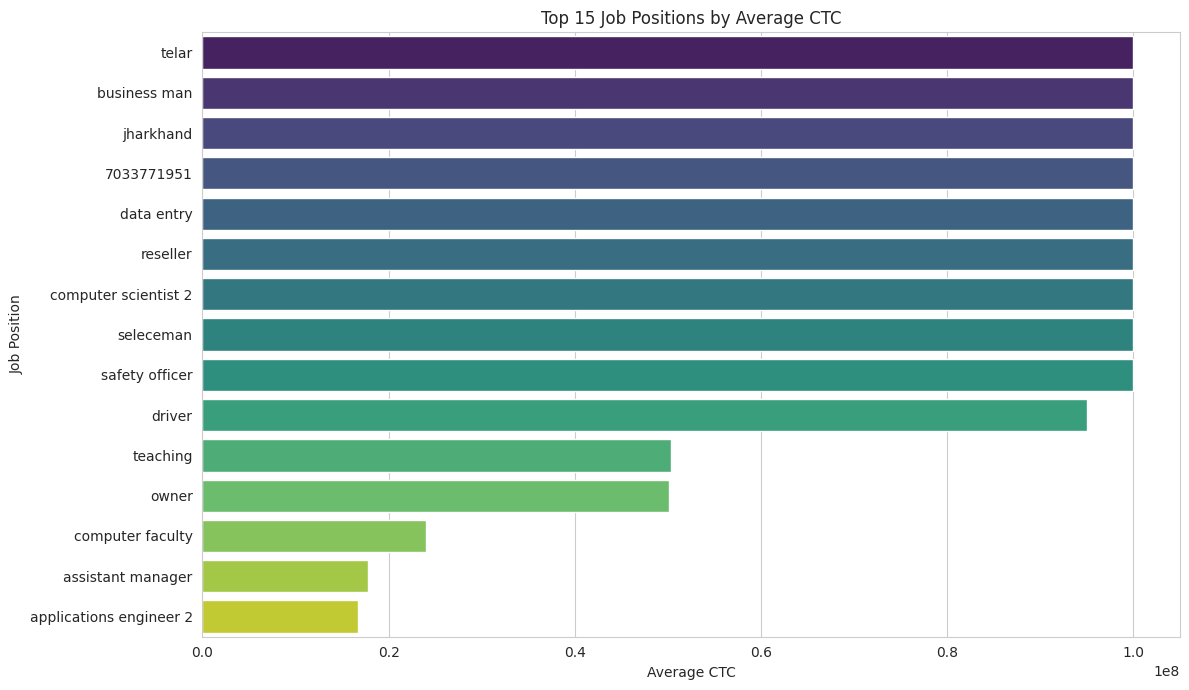

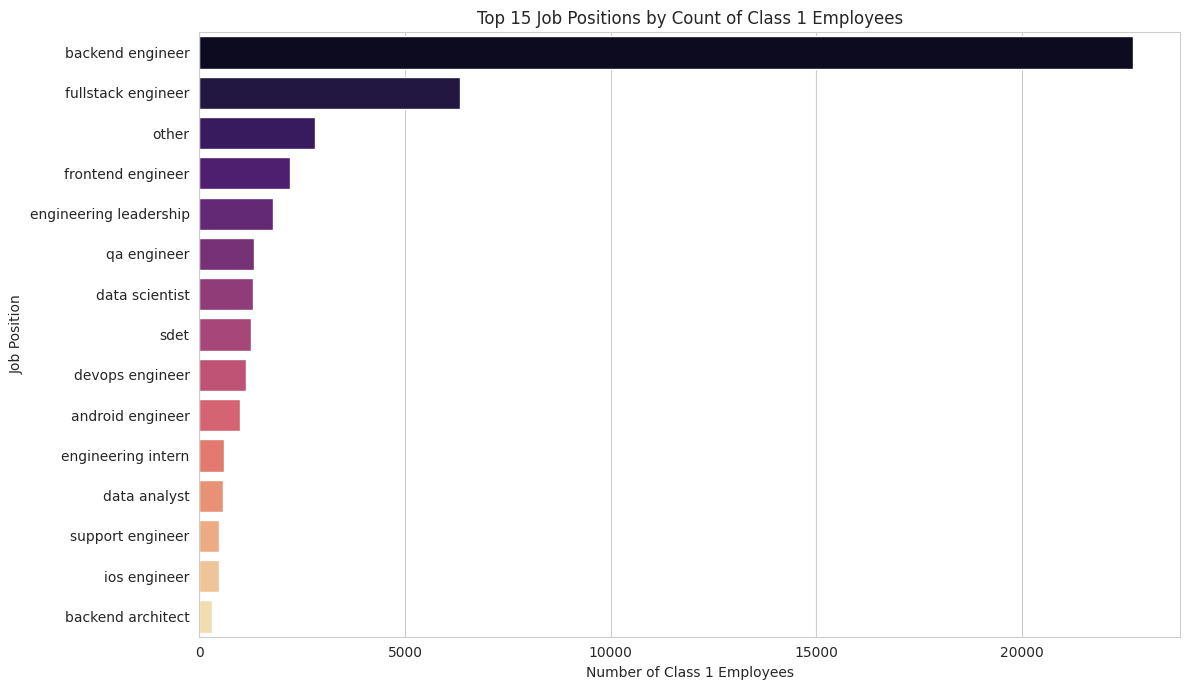

In [129]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# --- Metric 1: Top Job Positions by Average CTC ---
avg_ctc_by_job = df_students.groupby('job_position')['ctc'].mean().sort_values(ascending=False).head(15)

plt.figure(figsize=(12, 7))
sns.barplot(x=avg_ctc_by_job.values, y=avg_ctc_by_job.index, palette='viridis', hue=avg_ctc_by_job.index, legend=False)
plt.title('Top 15 Job Positions by Average CTC')
plt.xlabel('Average CTC')
plt.ylabel('Job Position')
plt.tight_layout()
plt.show()

# --- Metric 2: Top Job Positions by Count of Class 1 Employees ---
# Filter for Class 1 employees
class_1_jobs = df_students[df_students['class_flag'] == 1]

# Count Class 1 employees per job position
count_class1_by_job = class_1_jobs['job_position'].value_counts().head(15)

plt.figure(figsize=(12, 7))
sns.barplot(x=count_class1_by_job.values, y=count_class1_by_job.index, palette='magma', hue=count_class1_by_job.index, legend=False)
plt.title('Top 15 Job Positions by Count of Class 1 Employees')
plt.xlabel('Number of Class 1 Employees')
plt.ylabel('Job Position')
plt.tight_layout()
plt.show()

## Analysis: Relationship between Years of Experience and Job Position Performance

To understand how years of experience influence job position performance, we will visualize two key aspects:
1.  **Average CTC by Years of Experience for Top Job Positions**: This will show the typical salary progression within specific roles.
2.  **Proportion of Class 1 Employees by Years of Experience for Top Job Positions**: This will highlight how the concentration of high-performing individuals changes with experience within different roles.

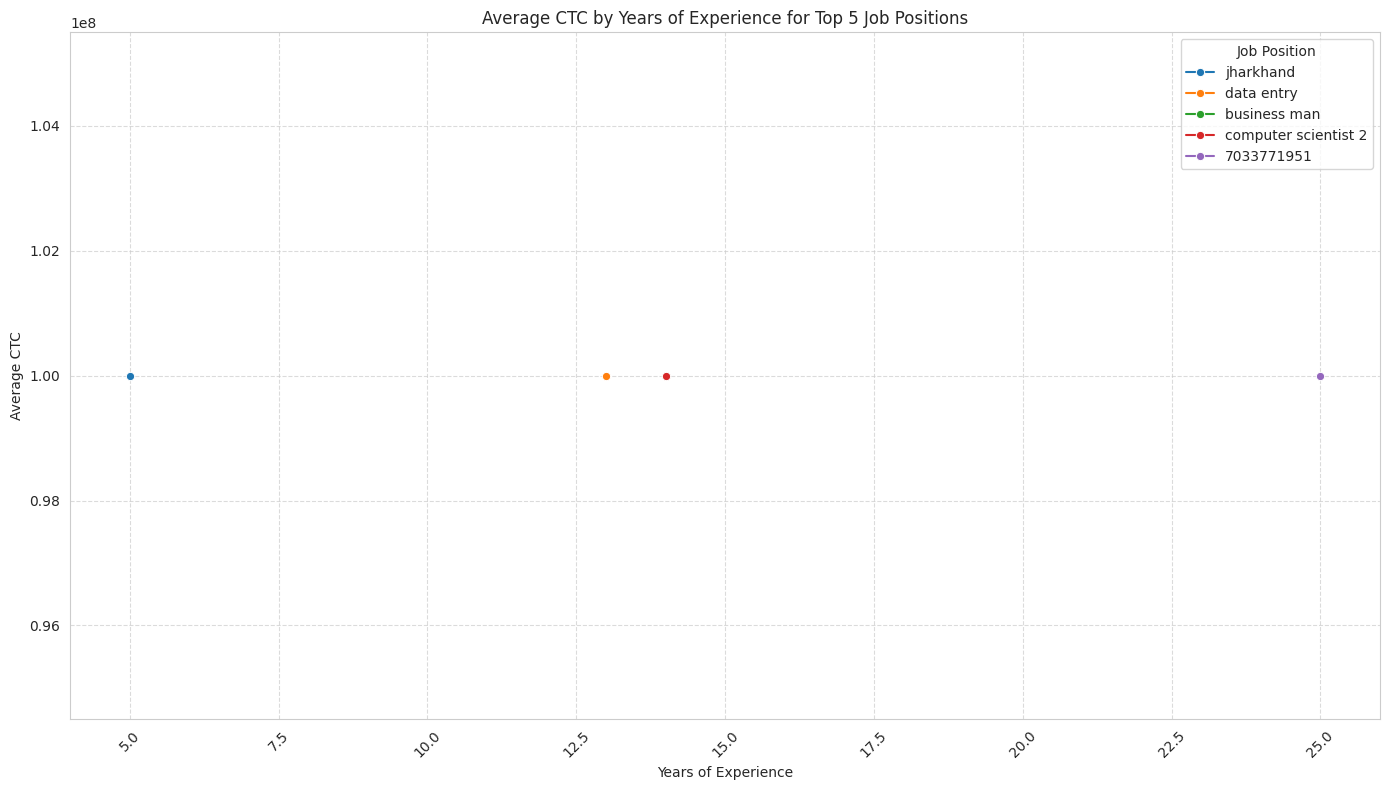

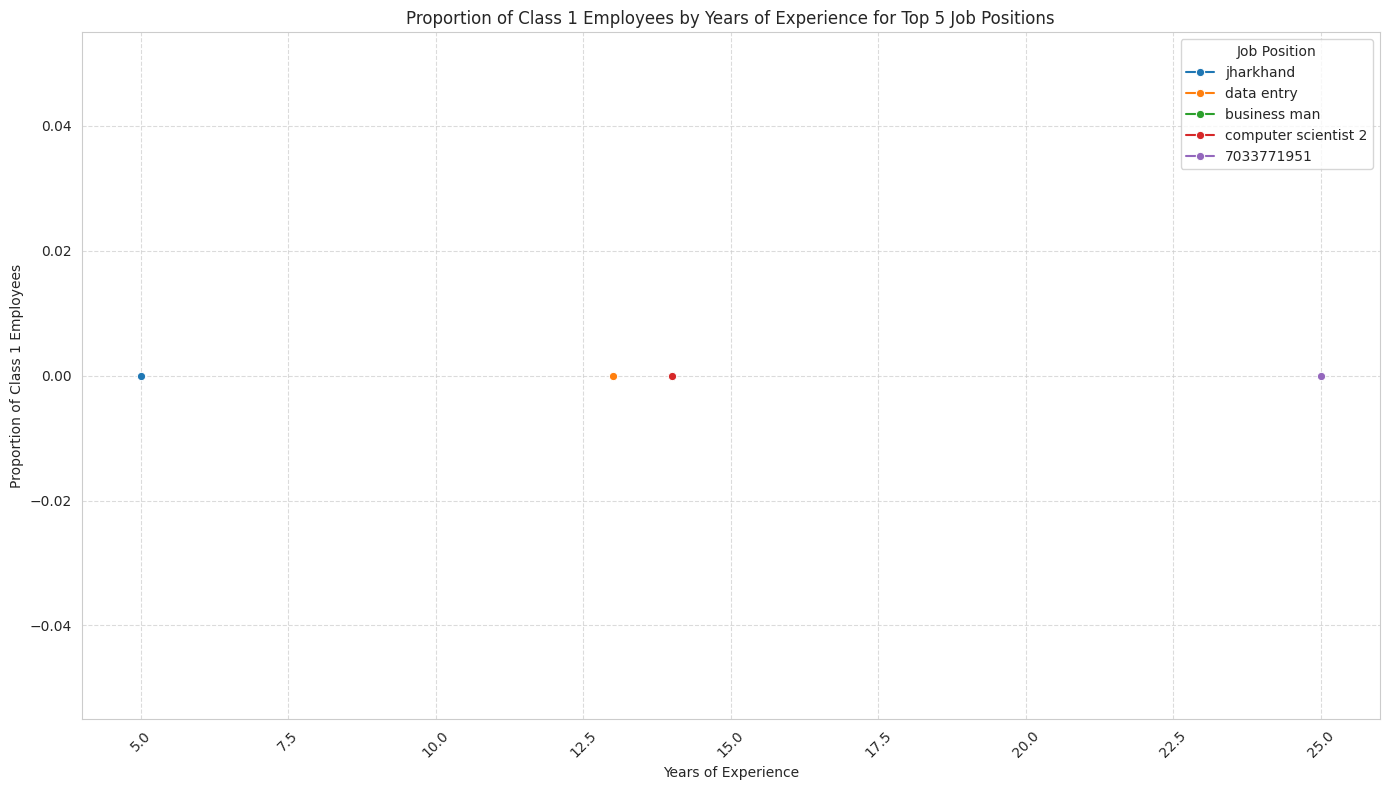

In [130]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# Get top 5 job positions by average CTC for focused analysis
top_5_jobs = df_students.groupby('job_position')['ctc'].mean().nlargest(5).index.tolist()

# --- Metric 1: Average CTC by Years of Experience for Top Job Positions ---
df_top_jobs_ctc = df_students[df_students['job_position'].isin(top_5_jobs)]
avg_ctc_exp_job = df_top_jobs_ctc.groupby(['years_of_experience', 'job_position'])['ctc'].mean().reset_index()

plt.figure(figsize=(14, 8))
sns.lineplot(data=avg_ctc_exp_job, x='years_of_experience', y='ctc', hue='job_position', marker='o', palette='tab10')
plt.title('Average CTC by Years of Experience for Top 5 Job Positions')
plt.xlabel('Years of Experience')
plt.ylabel('Average CTC')
plt.xticks(rotation=45)
plt.legend(title='Job Position')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# --- Metric 2: Proportion of Class 1 Employees by Years of Experience for Top Job Positions ---
# Calculate total employees per (experience, job position) group
total_employees_exp_job = df_top_jobs_ctc.groupby(['years_of_experience', 'job_position']).size().reset_index(name='total_employees')

# Calculate Class 1 employees per (experience, job position) group
class_1_employees_exp_job = df_top_jobs_ctc[df_top_jobs_ctc['class_flag'] == 1].groupby(['years_of_experience', 'job_position']).size().reset_index(name='class_1_employees')

# Merge and calculate proportion
df_class1_proportion = pd.merge(total_employees_exp_job, class_1_employees_exp_job, on=['years_of_experience', 'job_position'], how='left')
df_class1_proportion['class_1_employees'] = df_class1_proportion['class_1_employees'].fillna(0) # Fix for FutureWarning
df_class1_proportion['proportion_class_1'] = df_class1_proportion['class_1_employees'] / df_class1_proportion['total_employees']

plt.figure(figsize=(14, 8))
sns.lineplot(data=df_class1_proportion, x='years_of_experience', y='proportion_class_1', hue='job_position', marker='o', palette='tab10')
plt.title('Proportion of Class 1 Employees by Years of Experience for Top 5 Job Positions')
plt.xlabel('Years of Experience')
plt.ylabel('Proportion of Class 1 Employees')
plt.xticks(rotation=45)
plt.legend(title='Job Position')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Unsupervised Learning: Clustering

With our data now encoded and standardized, we can proceed with unsupervised clustering techniques. This involves several steps:

1.  **Checking Clustering Tendency**: Determine if the data contains inherent clusters or if it's mostly uniform noise.
2.  **Elbow Method**: A heuristic to determine the optimal number of clusters for K-Means.
3.  **K-Means Clustering**: Apply the K-Means algorithm to segment the data.
4.  **Hierarchical Clustering**: Explore an alternative clustering approach.

### Checking Clustering Tendency

Before applying clustering algorithms, it's good practice to assess if the data has a natural tendency to form clusters. While formal statistical tests exist (e.g., Hopkins Statistic), a simple visual check can sometimes provide initial insights. For high-dimensional data, visualizing all dimensions at once is hard. We can use a heatmap of the correlation matrix or a sample of PCA components to get a sense of structure. Given the scope, we'll proceed directly to the Elbow Method, which implicitly assumes some clustering tendency.

### Elbow Method for Optimal K (K-Means)

The Elbow method helps us find the optimal number of clusters (K) for K-Means clustering. It plots the Within-Cluster Sum of Squares (WCSS) against the number of clusters. The 'elbow' point in the plot, where the rate of decrease in WCSS sharply changes, is often considered the optimal K.

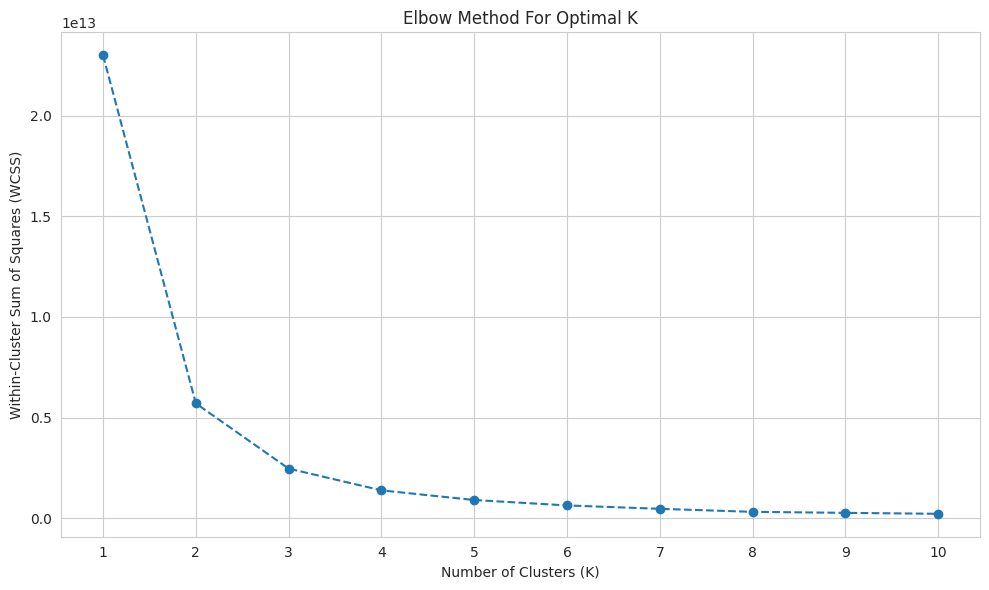

Please examine the plot above to identify the 'elbow' point, which suggests the optimal K. We will proceed with K=4 for demonstration purposes, but you may choose a different value based on your observation.


In [124]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Prepare the data for clustering (all columns in df_clustering)
X = df_clustering.values # Get the numerical values from the DataFrame

wcss = []
# Try different numbers of clusters from 1 to 10 (or a reasonable range)
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_) # inertia_ is the WCSS

# Plot the Elbow Method graph
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.xticks(range(1, 11))
plt.grid(True)
plt.tight_layout()
plt.show()

print("Please examine the plot above to identify the 'elbow' point, which suggests the optimal K. We will proceed with K=4 for demonstration purposes, but you may choose a different value based on your observation.")

### K-Means Clustering

Now that we have an idea of the optimal number of clusters (let's assume K=4 based on the typical 'elbow' point for demonstration), we will apply the K-Means algorithm to segment our employee data.

In [125]:
from sklearn.cluster import KMeans

# Choose the optimal number of clusters based on the Elbow Method plot. Let's assume K=4 for now.
optimal_k = 4 # This can be changed based on observation of the elbow plot

kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)

# Fit K-Means to the preprocessed data
df_clustering['kmeans_cluster'] = kmeans.fit_predict(X)

### Visualizing K-Means Clusters with PCA

To visualize the high-dimensional clusters in a 2D or 3D space, we can use Dimensionality Reduction techniques like Principal Component Analysis (PCA). PCA helps us capture the most variance in the data with a smaller number of components, making visualization feasible.

In [126]:
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

# Instantiate PCA to reduce to 2 components for 2D visualization
pca = PCA(n_components=2)

# Fit PCA on the scaled data (X) and transform it
pca_components = pca.fit_transform(X)

# Create a DataFrame for the PCA components
df_pca = pd.DataFrame(data = pca_components, columns = ['principal_component_1', 'principal_component_2'])

# Add the K-Means cluster labels to the PCA DataFrame
df_pca['kmeans_cluster'] = df_clustering['kmeans_cluster'].astype('category')

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


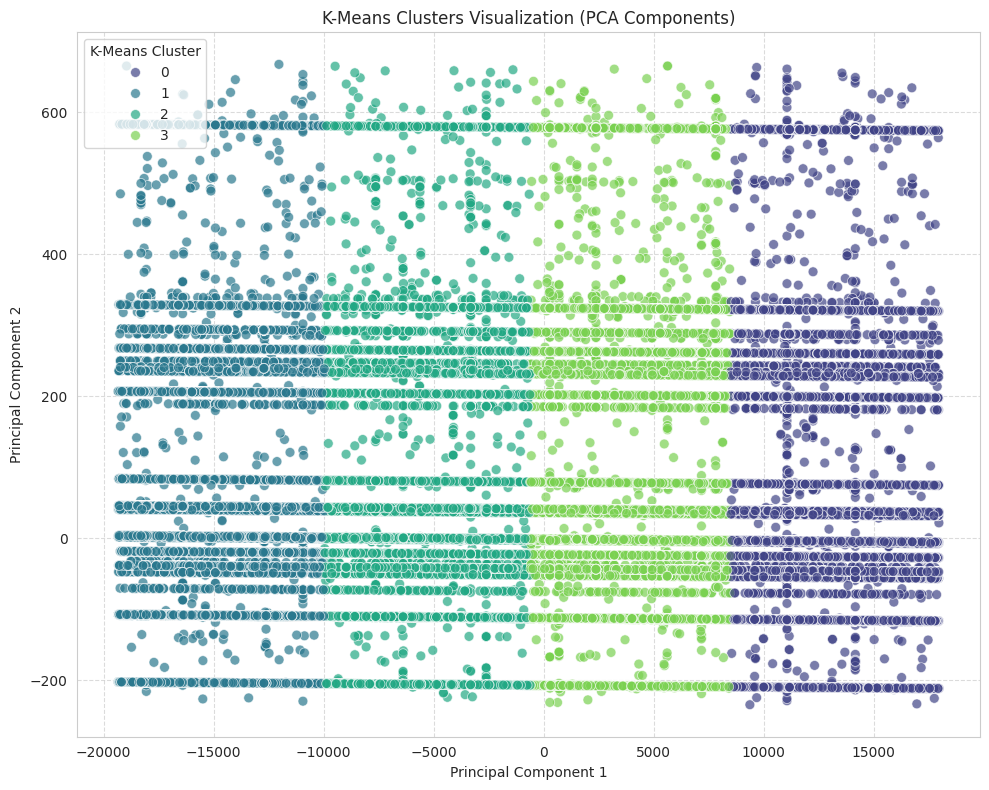

In [127]:
# Create a scatter plot to visualize the clusters
fig = plt.figure(figsize=(10, 8))
sns.scatterplot(x='principal_component_1', y='principal_component_2', hue='kmeans_cluster', palette='viridis', data=df_pca, s=50, alpha=0.7)
plt.title('K-Means Clusters Visualization (PCA Components)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='K-Means Cluster')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Hierarchical Clustering

Hierarchical clustering builds a hierarchy of clusters. We can visualize this hierarchy using a dendrogram. For large datasets, hierarchical clustering can be computationally expensive, so we'll apply it to a sample of our data if `df_clustering` is very large.

Using a sample of 5000 records for Hierarchical Clustering due to dataset size.


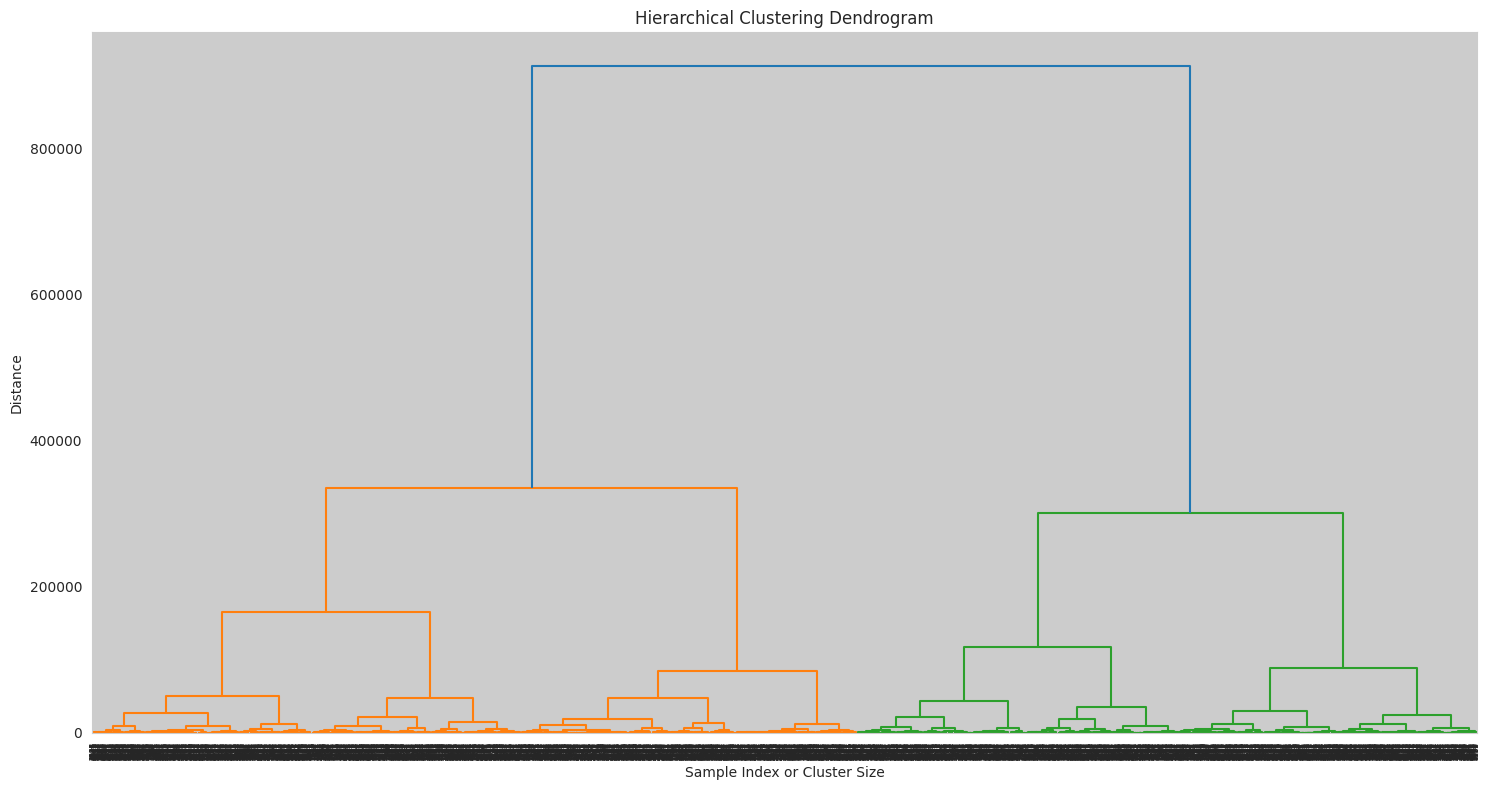

In [128]:
from scipy.cluster.hierarchy import dendrogram, linkage

# For very large datasets, hierarchical clustering can be computationally intensive.
# Let's take a sample of the data for this demonstration if the dataset is large.
sample_size = 5000 # You can adjust this sample size

if len(df_clustering) > sample_size:
    df_sample = df_clustering.sample(n=sample_size, random_state=42)
    X_sample = df_sample.values
    print(f"Using a sample of {sample_size} records for Hierarchical Clustering due to dataset size.")
else:
    df_sample = df_clustering
    X_sample = X
    print("Using the entire dataset for Hierarchical Clustering.")

# Perform hierarchical clustering using 'ward' linkage
# 'ward' minimizes the variance of the clusters being merged.
linked = linkage(X_sample, method='ward')

# Plot the dendrogram
plt.figure(figsize=(15, 8))
dendrogram(linked,
           orientation='top',
           distance_sort='descending',
           show_leaf_counts=True)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Sample Index or Cluster Size')
plt.ylabel('Distance')
plt.tight_layout()
plt.show()